# Phase 8: Report figures, tables and results webpage

We assembled the report's figures, its two results tables, every number it cites and the course results webpage from the saved results of Phases 0–7, without changing any result and without reading a test row. Every figure, table and page uses descriptive model names: the unpaired CycleGAN, CycleGAN + composition labels, CycleGAN + cross-fitted labels and paired ridge regression are M1, M2, B-cf and ridge + spread in the other notebooks and in the result files. The headline results are those of the single test evaluation (Phase 7; 119 pairs, 14 donors). The unpaired CycleGAN is not beyond the unpaired accuracy–realism frontier: its margin is +0.105 (95% CI −0.259 to 0.290) in single-cell → bulk and −0.372 (95% CI −0.705 to −0.006) in bulk → single-cell. Composition labels from pair-trained networks raise composition R² read from marker genes by +0.174 (95% CI 0.108–0.331) and +0.140 (95% CI 0.079–0.267). Paired ridge regression is more accurate than the unpaired CycleGAN by +0.375 (95% CI 0.302–0.478) and +0.515 (95% CI 0.406–0.682) in centered R². New figures drawn from saved models on validation data show the mechanism behind these results and what the translations look like.

## 1. Aim

The report and the webpage must present the test results exactly as they were scored, with each figure showing one comparison and each number traceable to a result table. This phase builds that presentation layer: a schematic of how much pair information each model uses, the mechanism and qualitative figures that explain the test outcome, the LaTeX tables and number macros the report is typeset from, and a static results page.

## 2. Data

- **Test split** (119 pairs, 14 donors): only its saved Phase 7 result tables and figures are used. No test expression row is selected; the split labels alone give the test counts. The test-touch record of Phase 7 (one scoring run and one presentation-only re-run) is asserted to hold exactly its two entries before and after this notebook.
- **Validation split** (135 pairs, 14 donors): the translations drawn in Figures 8.4(a–c) and 8.5, recomputed from saved models.
- **Training split** (582 pairs, 68 donors): the evaluators, the principal components of Figure 8.5 and the paired reference ridge + spread, all fit on training data in earlier phases; the training halves supply the random real profiles of Figure 8.5.

## 3. Methods

**Metrics** (defined in Phase 1, §3, and Phase 3, §3). Accuracy is centered R², the median over pairs of $1 - \lVert \hat y - y\rVert^2 / \lVert y - \mu\rVert^2$ with $\mu$ the target domain's training mean. Realism is $1 - 2\,\lvert \text{AUROC} - 0.5\rvert$ of a classifier trained to tell translations from real profiles on the top 10 target principal components, a classifier two-sample test (Lopez-Paz and Oquab, 2017). The unpaired accuracy–realism frontier is the best realism at each accuracy among blends of two of mean shift, ComBat (Johnson et al., 2007), CORAL (Sun et al., 2016) and the training-target mean, fit on the training halves; a model's margin is its realism minus the frontier's realism at its accuracy. Composition R² is the mean per-class R² of a ridge readout of composition from 28 lineage marker genes (Phase 2). The unpaired CycleGAN (Zhu et al., 2017; M1) uses no pairs; CycleGAN + composition labels (M2) adds a composition loss through networks trained on pairs; CycleGAN + cross-fitted labels (B-cf, Phase 5) takes each label from a network that never saw that donor; paired ridge regression (ridge + spread) is fit on all training pairs.

**Figures.**
- Figure 8.1 is a schematic and uses no data.
- Figures 8.2, 8.3 and 8.S1 redraw the Phase 7 test figures 7.1, 7.3 and 7.2 with descriptive labels, from saved results only. Every point comes from the Phase 7 result tables, and the validation positions from Phase 3's. The test frontier was drawn in Figure 7.1 but not saved as a table, so it is read from that figure's vector path: each panel's axes are calibrated on the three baselines' saved test values and the line at centered R² = 0 (asserted within 0.002), and the traced curve is asserted to pass within 0.005 of the saved frontier value at the unpaired CycleGAN's accuracy. No test row is read. Figure 8.2 shows the locked models and the cross-fitted variant; the averaged-weight versions of the locked models are in Table 2.
- Figure 8.4(a–c) is redrawn from the Phase 4 run logs of the unpaired CycleGAN and CycleGAN + composition labels with fresh seeds 3–5 (each run's late-training mean is asserted equal to Phase 4's table) and from the Phase 6 move-decomposition table; the horizontal lines are the marker-gene composition of mean shift and ComBat fit on the training halves and applied to the validation sources. Figure 8.4(d) is drawn from the Phase 7 within-donor table.
- Figures 8.5 and 8.S2 project every validation translation onto the top two principal components of the target domain (fit on the training targets) and join it to its true partner. The translators are the generator start, the unpaired CycleGAN and CycleGAN + composition labels (locked, seed 0, checked against their registry hashes), paired ridge regression fit on all training pairs (its validation centered R² is asserted equal to Phase 3's) and one real training-half profile drawn at random per source (draw seed 0). Every validation sample is drawn, so nothing is selected.

**Tables and numbers.** Every value is read from a result table and formatted as the notebooks print it (three decimals, a leading sign for differences and margins, CIs as "lower to upper"); readings and labels are copied verbatim from the result tables. The kind of each margin in Table 2 is recovered without test rows: a margin is an accuracy lead when the model's centered R² minus its margin equals the frontier's highest accuracy, which the two paired regressions give identically (asserted).
- Figure 8.S3 places the locked models on the validation accuracy–realism plane, with the Phase 1 frontier of the first training split.

## 4. Results

### 4.1 Setup and guards

The first code cell records the setup stamp, checks that the test-touch record holds exactly its two entries, and restricts every row selection to the training and validation splits.

In [1]:
import os, re, sys, json, shutil, hashlib, pickle, warnings, zlib
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
from IPython.display import Image, Markdown, display
from scipy.linalg import LinAlgWarning

from dgm import paths, report as rp, translation as tr
from dgm.frontier import envelope
from dgm import composition as comp
from dgm.models import canonical_hash, list_hash, pairs_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)
info = setup(seed=0, notebook="phase8_figures.ipynb")
comp.deterministic()
R = {k: paths.results_dir(k) for k in range(8)}
RESULTS, FIG = paths.results_dir(8), paths.results_dir(8, "figures")
REPORT, WEB = ROOT / "report", ROOT          # the results page lives at the repository root
for p_ in (REPORT / "figures", REPORT / "tables", WEB / "assets"):
    p_.mkdir(parents=True, exist_ok=True)
TOUCH = R[7] / "test_touch.json"
assert len(json.loads(TOUCH.read_text())) == 2, "the test-touch record must hold exactly its two entries"

ctx0 = tr.SoundLife(0)                                         # training evaluators, validation rows only
P, va = ctx0.pairs, ctx0.va
def rows(split):
    assert split in ("train", "val"), "Phase 8 never selects test rows"
    return P.idx(split)
assert (va == rows("val")).all()
DIRS = tr.DIRECTIONS
def show_caption(name):
    f = FIG / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

# Descriptive names for every figure, table and the webpage. The other notebooks and the result files use short names:
# M1, M2 and B-cf for the three CycleGANs, ridge + spread for paired ridge regression, OT-s for optimal-transport retrieval.
NAME = {"M1": "unpaired CycleGAN", "M2": "CycleGAN + composition labels", "B-cf": "CycleGAN + cross-fitted labels",
        "ridge + spread": "paired ridge regression", "ridge": "paired ridge, not spread out", "paired MLP": "paired neural network",
        "OT-s": "optimal-transport retrieval", "no-information reference": "random real profile",
        "same-donor reference": "another draw of the same donor"}
SHORT_NAMES = re.compile(r"(?<![\w-])(M1|M2|B-cf|H1|H2|H3|OT-s|halving-1)(?![\w-])")
def describe(s):
    """A string from a result file with the short model and hypothesis names replaced by descriptive ones."""
    s = s.replace("M2's composition networks were", "the composition networks were")
    for k, v in (("not compared with H1", "not compared with the frontier hypothesis"),
                 ("no halving-1 check", "no check on the second split of the training donors"),
                 ("B-cf", NAME["B-cf"]), ("M1", NAME["M1"]), ("M2", NAME["M2"]), ("OT-s", NAME["OT-s"])):
        s = re.sub(rf"(?<![\w-]){re.escape(k)}(?![\w-])", v, s)
    assert not SHORT_NAMES.search(s), s
    return s
GAN_COL = {"M1": INK, "M2": SERIES[6], "ridge + spread": SERIES[2]}
DIR_COL = {d: DOMAIN["bulk" if d == "S->B" else "single-cell"] for d in DIRS}   # colored by the target domain

<env>/lib/python3.10/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


commit: unknown | notebook_source: 5917e99752e4 (not in HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: False


### 4.2 Report figures

**Figure 8.1, the pairing ladder,** is a schematic: the three uses of pair information and the comparator that uses none.

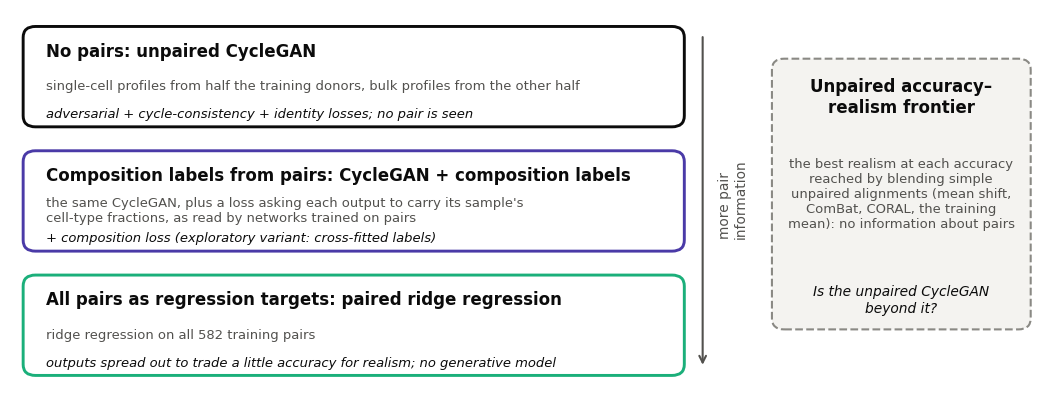

**Three uses of pair information, judged against a comparator that has none.** The unpaired CycleGAN trains on single-cell pseudobulk profiles from one half of the training donors and whole-blood bulk profiles from the other half, so it never sees a pair; it uses adversarial, cycle-consistency and identity losses. CycleGAN + composition labels adds a loss asking each translation to carry its sample's cell-type fractions, as read by composition networks trained on pairs; in the exploratory cross-fitted variant, each label comes from a network that never saw that sample's donor. Paired ridge regression regresses on all 582 training pairs; its outputs are spread out from the average by a factor chosen on the training donors, trading a little accuracy for realism. The arrow orders the three by how much pair information they use. The unpaired accuracy–realism frontier (dashed box) is the best realism that blends of simple unpaired alignments (mean shift, ComBat, CORAL and the training-target mean, fit on the same halves) reach at each accuracy; it carries no information about pairs. The first pre-stated question asks whether the unpaired CycleGAN lies beyond it.

In [2]:
fig, ax = figure("double", 2.6)
ax.set_xlim(0, 10); ax.set_ylim(0.3, 4.4); ax.axis("off")
RUNGS = [("No pairs: unpaired CycleGAN", "single-cell profiles from half the training donors, bulk profiles from the other half",
          "adversarial + cycle-consistency + identity losses; no pair is seen", INK, 3.2),
         ("Composition labels from pairs: CycleGAN + composition labels",
          "the same CycleGAN, plus a loss asking each output to carry its sample's\ncell-type fractions, as read by networks trained on pairs",
          "+ composition loss (exploratory variant: cross-fitted labels)", SERIES[6], 1.85),
         ("All pairs as regression targets: paired ridge regression", "ridge regression on all 582 training pairs",
          "outputs spread out to trade a little accuracy for realism; no generative model", SERIES[2], 0.5)]
for title, uses, how, col, y in RUNGS:
    ax.add_patch(FancyBboxPatch((0.1, y), 6.45, 1.05, boxstyle="round,pad=0.02,rounding_size=0.12", fc="white", ec=col, lw=1.4))
    ax.text(0.3, y + 0.8, title, fontsize=8, fontweight="bold", color=INK, va="center")
    ax.text(0.3, y + 0.42, uses, fontsize=6.3, color=INK_2, va="center")
    ax.text(0.3, y + 0.12, how, fontsize=6.3, color=INK, va="center", style="italic")
ax.annotate("", xy=(6.75, 0.55), xytext=(6.75, 4.2), arrowprops=dict(arrowstyle="->", color=INK_2, lw=1))
ax.text(6.9, 2.4, "more pair\ninformation", fontsize=6.6, color=INK_2, va="center", rotation=90)
ax.add_patch(FancyBboxPatch((7.45, 1.0), 2.5, 2.9, boxstyle="round,pad=0.02,rounding_size=0.12", fc="#f4f3f0", ec=MUTED, lw=1, ls="--"))
ax.text(8.7, 3.5, "Unpaired accuracy–\nrealism frontier", fontsize=8, fontweight="bold", ha="center", va="center")
ax.text(8.7, 2.45, "the best realism at each accuracy\nreached by blending simple\nunpaired alignments (mean shift,\nComBat, CORAL, the training\nmean): no information about pairs",
        fontsize=6.3, ha="center", va="center", color=INK_2)
ax.text(8.7, 1.3, "Is the unpaired CycleGAN\nbeyond it?", fontsize=6.6, ha="center", va="center", style="italic")
save_show(fig, FIG, "8.1_pairing_ladder")
show_caption("8.1_pairing_ladder")

**Figures 8.2, 8.3 and 8.S1** redraw the Phase 7 test figures 7.1, 7.3 and 7.2 with descriptive labels, from saved results only; the test frontier is traced from Figure 7.1 (Methods).

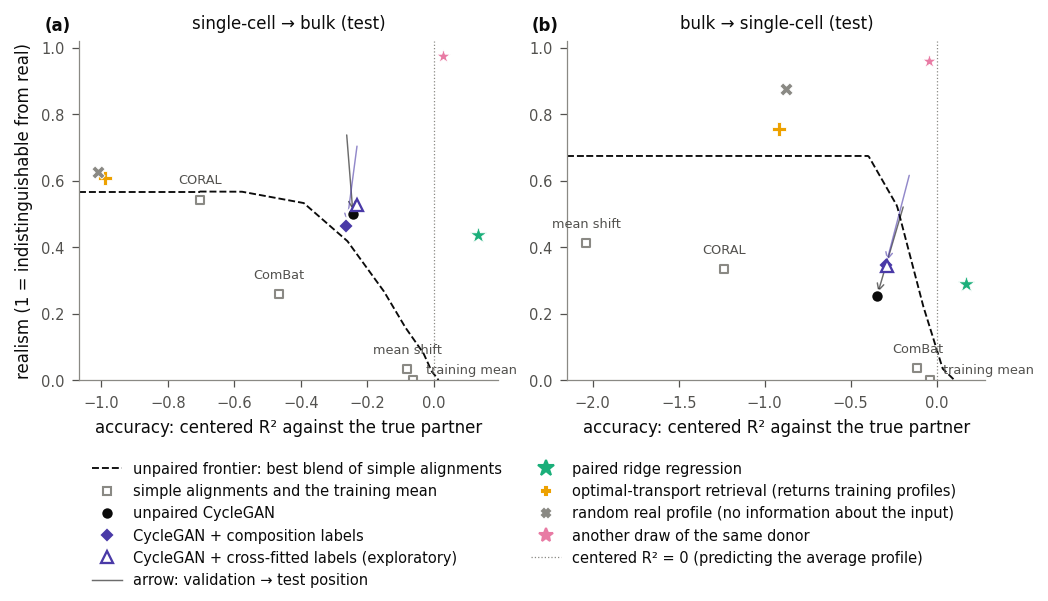

**On test, the unpaired CycleGAN is not distinguishable from the unpaired accuracy–realism frontier in single-cell → bulk and lies inside it in bulk → single-cell, while real profiles that carry no information about the source lie beyond it.** Each panel places the translations of the 119 test sources (14 donors) by accuracy (centered R² against the true partner, x-axis) and realism (1 − 2|AUROC − 0.5| of a classifier trained to tell translations from real profiles; y-axis); higher is better on both. (a) Single-cell → bulk; (b) bulk → single-cell. Dashed curve: the unpaired accuracy–realism frontier on test, the best realism that blends of two of mean shift, ComBat, CORAL and the training-target mean reach at each accuracy, all fit on the training halves; it is flat to the left of its most realistic blend and is drawn flat to the axis edge. Gray squares: mean shift, ComBat, CORAL and the training mean, labeled. Because a blend can be more realistic than either of its two methods, the frontier can lie above every single alignment, as in (b). Black circle: the unpaired CycleGAN; purple diamond: CycleGAN + composition labels (both as locked before test, at the checkpoints chosen on validation, mean of 3 seeds); open purple triangle: CycleGAN + cross-fitted labels (exploratory; averaged weights, no checkpoint selection). Arrows run from the two locked models' validation positions to their test positions. Green star: paired ridge regression on all training pairs. Yellow plus: optimal-transport retrieval, which returns one training profile per source. Gray cross: one real training profile drawn at random per source. Pink star: another draw of the same donor. Dotted vertical line: centered R² = 0, the accuracy of predicting the average profile. The real and retrieved profiles beyond the frontier show that, on this realism measure, passing the frontier does not by itself mean that a translation carries information about its source. The unpaired CycleGAN's single-cell → bulk point lies above the frontier, but its margin's 95% CI includes 0 (Table 1). The frontier is traced from the vector path of Phase 7's Figure 7.1, calibrated on the baselines' saved test values; no test row was read again.

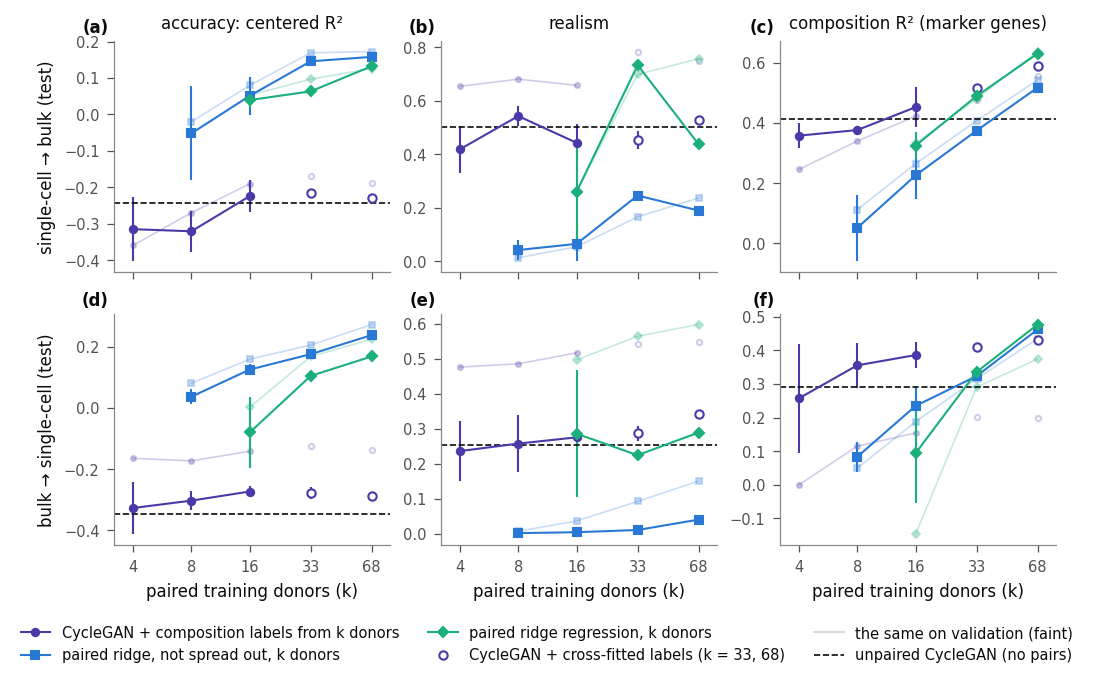

**On test, pairs buy far more accuracy as regression targets than as composition labels, and labels give more composition when few donors are paired.** Each panel plots one measure on the 119 test pairs (14 donors) against the number of paired training donors k (log scale); higher is better. Columns: (a, d) accuracy (centered R²), (b, e) realism, (c, f) composition R² read by a marker-gene readout. Rows: (a–c) single-cell → bulk, (d–f) bulk → single-cell. Purple: CycleGAN + composition labels whose composition networks are trained on k donors' pairs (averaged weights; bars ± SD over 3 seeds). At k = 4, 8 and 16 the donors are nested, so the SD includes the draw of donors. At k = 33 and 68 (open, unconnected markers) the labels are cross-fitted, so these points are not on the same footing; k = 68 is CycleGAN + cross-fitted labels, whose bar is omitted. Blue and green: paired ridge regression without and with its outputs spread out, trained on the same k donors' pairs (± SD over the seeds' donor draws at k = 8 and 16; single fits at 33 and 68). Faint lines and markers: the same measures on validation. Dashed line: the unpaired CycleGAN (no pairs) on test. All points are scored on test only; nothing was chosen on them.

<env>/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


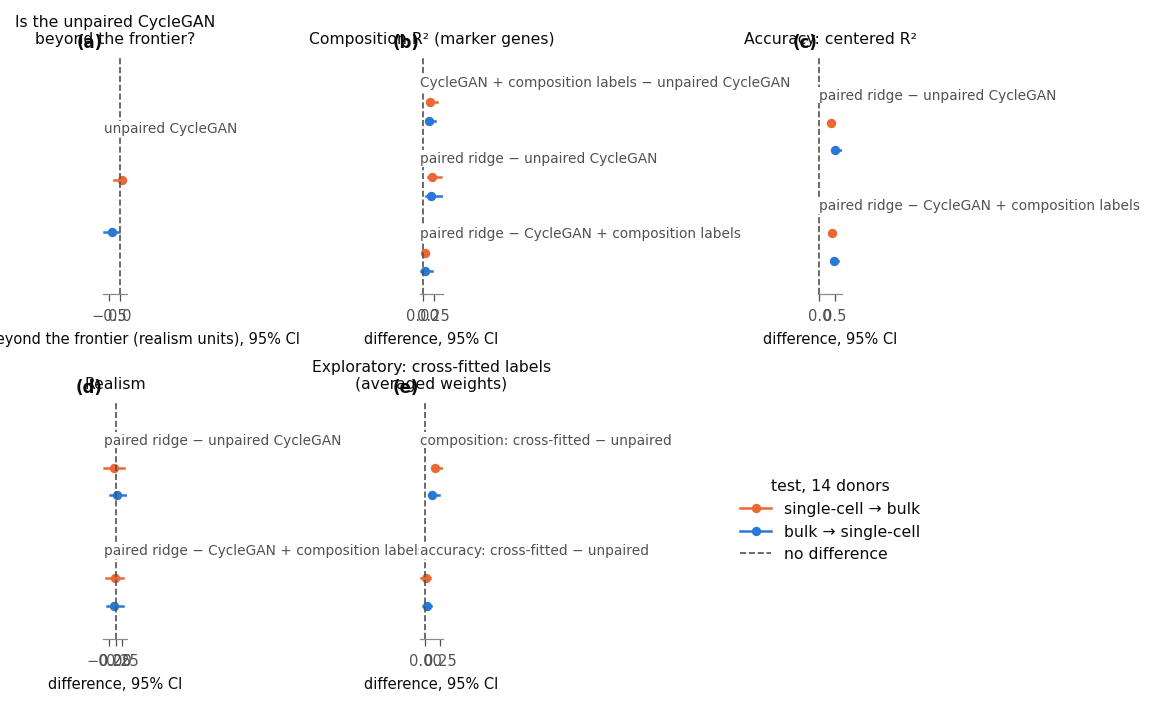

**The unpaired CycleGAN is not beyond the unpaired accuracy–realism frontier; composition labels help in both directions; paired ridge regression is far more accurate than either CycleGAN.** Point estimates and paired donor-bootstrap 95% CIs (1,000 resamples of the 14 test donors; 119 pairs); orange is single-cell → bulk and blue is bulk → single-cell. (a) The unpaired CycleGAN's margin beyond the frontier, in realism units; the frontier is rebuilt on each resample. (b) Composition R² read by the marker-gene readout: CycleGAN + composition labels minus the unpaired CycleGAN, and paired ridge regression minus each of them. (c) The same paired-ridge differences in accuracy (centered R²) and (d) in realism. (e) Exploratory: CycleGAN + cross-fitted labels minus the unpaired CycleGAN, both with averaged weights, in composition and accuracy. The dashed line marks no difference. The four primary intervals are those of (a) and the first row of (b), per direction, without multiplicity correction.

In [3]:
# Figures 8.2, 8.3 and 8.S1 redraw the Phase 7 test figures 7.1, 7.3 and 7.2 with descriptive labels, from saved results only.
models = pd.read_csv(R[7] / "models_test.csv"); h1 = pd.read_csv(R[7] / "h1_test.csv"); h2 = pd.read_csv(R[7] / "h2_test.csv")
h3 = pd.read_csv(R[7] / "h3_test.csv"); bcf = pd.read_csv(R[7] / "bcf_test.csv"); p3 = pd.read_csv(R[3] / "models_vs_baselines_val.csv")
PT = lambda d, n: models[(models.direction == label(d)) & (models.model == n)].iloc[0]
by = lambda t, d: t[t.direction == d].iloc[0]

def traced_frontier(pdf):
    """The unpaired frontier on the full test set as Phase 7 drew it in Figure 7.1 (its dashed vector path), in data units.
    Phase 7 plotted this curve but did not save it as a table, so it is read from the figure; no test row is read here.
    Each panel's axes are calibrated from the three baseline markers, whose test values are in models_test.csv, and the
    dotted line at centered R² = 0; the y-axis spans realism 0 to 1.02."""
    raw = pdf.read_bytes()
    streams = []
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            streams.append(zlib.decompress(m.group(1)).decode("latin1"))
        except zlib.error:
            pass
    page = max(streams, key=len)
    blocks = re.findall(r"q ([\d.]+) ([\d.]+) ([\d.]+) ([\d.]+) re W n(.*?)(?=\bQ\b)", page, re.S)
    pts = lambda body: np.array(re.findall(r"(-?[\d.]+) (-?[\d.]+) [ml]\b", body), float)
    out = []
    for x_clip, d in zip(sorted({float(b[0]) for b in blocks}), DIRS):
        mine = [(float(b[1]), float(b[3]), " ".join(b[4].split())) for b in blocks if float(b[0]) == x_clip]
        y0, h = mine[0][0], mine[0][1]
        curve = [pts(b) for _, _, b in mine if "[ 3.33 1.44 ] 0 d" in b and len(pts(b)) > 2]
        squares = [pts(b).mean(0) for _, _, b in mine if "0.5411764706 0.537254902 0.5176470588 RG 1 g" in b and b.endswith("h B")]
        zero = [pts(b)[0, 0] for _, _, b in mine if "[ 0.6 0.99 ] 0 d" in b]
        assert len(curve) == 1 and len(squares) == 3 and len(zero) == 1, (len(curve), len(squares), len(zero))
        known = [(PT(d, n)["r2_centered"], PT(d, n)["realism"]) for n in ("mean shift", "ComBat", "CORAL")]   # Phase 7's plotting order
        ax_, bx_ = np.linalg.lstsq(np.array([[k[0], 1.0] for k in known] + [[0.0, 1.0]]), np.array([s[0] for s in squares] + zero), rcond=None)[0]
        to_r2, to_real = (lambda u: (u - bx_) / ax_), (lambda v: (v - y0) / h * 1.02)
        err = max(max(abs(to_r2(s[0]) - k[0]), abs(to_real(s[1]) - k[1])) for s, k in zip(squares, known))
        assert err < 2e-3, err                                   # the calibration reproduces the baselines' test values
        c = curve[0][np.argsort(curve[0][:, 0], kind="stable")]
        out.append(pd.DataFrame({"direction": label(d), "r2_centered": to_r2(c[:, 0]), "realism": to_real(c[:, 1])}))
    return pd.concat(out, ignore_index=True)

FT = traced_frontier(R[7] / "figures" / "7.1_test_plane.pdf")
for d in DIRS:                                                   # the traced curve passes through Phase 7's saved frontier value at M1's accuracy
    f_, a_ = FT[FT.direction == label(d)], by(h1, label(d))
    assert abs(np.interp(a_["M1 centered R²"], f_.r2_centered, f_.realism) - a_["frontier at M1's accuracy"]) < 5e-3
FT.to_csv(RESULTS / "test_frontier_traced.csv", index=False)

# Figure 8.2: the test accuracy-realism plane
STY = {"M1": dict(marker="o", ms=6, color=INK, mfc=INK, mec="white"), "M2": dict(marker="D", ms=5.2, color=SERIES[6], mfc=SERIES[6], mec="white"),
       "B-cf (EMA)": dict(marker="^", ms=6, color=SERIES[6], mfc="white", mec=SERIES[6], mew=1.1)}
OTHER = (("ridge + spread", "*", 70, SERIES[2]), ("OT-s", "P", 40, SERIES[3]), ("no-information reference", "X", 40, MUTED), ("same-donor reference", "*", 50, SERIES[4]))
fig, ax = figure("double", 3.9, 1, 2)
for a, d in zip(ax, DIRS):
    f_ = FT[FT.direction == label(d)]
    a.plot(f_.r2_centered, f_.realism, color=INK, lw=0.9, ls="--", zorder=1)
    for n in ("mean shift", "ComBat", "CORAL", "training mean"):
        a.scatter(PT(d, n)["r2_centered"], PT(d, n)["realism"], s=18, marker="s", facecolor="white", edgecolor=MUTED, lw=1, zorder=2)
        tm = n == "training mean"                                # its label goes to the right, clear of mean shift's
        a.annotate(n, (PT(d, n)["r2_centered"], PT(d, n)["realism"]), xytext=(6, 2) if tm else (0, 6), textcoords="offset points",
                   fontsize=6.2, color=INK_2, ha="left" if tm else "center", va="bottom")
    for n in ("M1", "M2"):                                       # arrows from the locked models' validation positions (Phase 3)
        v = p3[(p3.direction == label(d)) & (p3.method == f"{n} (mean of 3 seeds)")].iloc[0]
        a.annotate("", xy=(PT(d, n)["r2_centered"], PT(d, n)["realism"]), xytext=(v["r2_centered"], v["realism"]),
                   arrowprops=dict(arrowstyle="->", color=STY[n]["color"], lw=0.7, alpha=0.6), zorder=3)
    for n, sty in STY.items():
        a.plot([PT(d, n)["r2_centered"]], [PT(d, n)["realism"]], ls="", zorder=5, **sty)
    for n, mk, s_, col in OTHER:
        a.scatter(PT(d, n)["r2_centered"], PT(d, n)["realism"], s=s_, marker=mk, color=col, edgecolor="white", lw=0.4, zorder=4)
    a.axvline(0, color=MUTED, lw=0.6, ls=":")
    x_lo = a.get_xlim()[0]                                       # F(r) is flat left of its most realistic blend: draw it to the axis edge
    a.plot([x_lo, f_.r2_centered.iloc[0]], [f_.realism.iloc[0]] * 2, color=INK, lw=0.9, ls="--", zorder=1)
    a.set_xlim(left=x_lo)
    a.set(xlabel="accuracy: centered R² against the true partner", ylabel="realism (1 = indistinguishable from real)" if d == "S->B" else "",
          title=f"{label(d)} (test)", ylim=(0, 1.02))
handles = [Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier: best blend of simple alignments"),
           Line2D([], [], ls="", marker="s", mfc="white", mec=MUTED, label="simple alignments and the training mean"),
           Line2D([], [], ls="", label=NAME["M1"], **STY["M1"]), Line2D([], [], ls="", label=NAME["M2"], **STY["M2"]),
           Line2D([], [], ls="", label=NAME["B-cf"] + " (exploratory)", **STY["B-cf (EMA)"]),
           Line2D([], [], color=INK, lw=0.7, alpha=0.6, label="arrow: validation → test position"),
           Line2D([], [], ls="", marker="*", ms=8, color=SERIES[2], label=NAME["ridge + spread"]),
           Line2D([], [], ls="", marker="P", color=SERIES[3], label=NAME["OT-s"] + " (returns training profiles)"),
           Line2D([], [], ls="", marker="X", color=MUTED, label=NAME["no-information reference"] + " (no information about the input)"),
           Line2D([], [], ls="", marker="*", ms=7, color=SERIES[4], label=NAME["same-donor reference"]),
           Line2D([], [], color=MUTED, lw=0.6, ls=":", label="centered R² = 0 (predicting the average profile)")]
fig.legend(handles=handles, loc="outside lower center", ncol=2)
panel_labels(ax)
save_show(fig, FIG, "8.2_test_plane")
show_caption("8.2_test_plane")

# Figure 8.3: what pairs buy on test, validation faint
pb, pbv = pd.read_csv(R[7] / "pairs_buy_test.csv"), pd.read_csv(R[6] / "pairs_buy_val.csv")
KS = [4, 8, 16, 33, 68]
STY3 = {"weakly paired GAN (EMA)": dict(color=SERIES[6], marker="o"), "ridge": dict(color=SERIES[0], marker="s"), "ridge + spread": dict(color=SERIES[2], marker="D")}
SHOW3 = {"weakly paired GAN (EMA)": "CycleGAN + composition labels from k donors", "ridge": NAME["ridge"] + ", k donors",
         "ridge + spread": NAME["ridge + spread"] + ", k donors"}
COLS3 = {"centered R²": "r2_centered", "realism": "realism", "marker composition R²": "marker composition R²"}
fig, ax = figure("double", 4.4, 2, 3, sharex=True)
for i, d in enumerate(DIRS):
    for j, mname in enumerate(COLS3):
        a = ax[i, j]
        for meth, sty in STY3.items():
            v = pbv[(pbv.direction == label(d)) & (pbv.method == meth) & (pbv.metric == mname)].sort_values("k")
            t = pb[(pb.direction == label(d)) & (pb.method == meth) & (pb.metric == mname)].sort_values("k")
            if meth.startswith("weakly"):                        # k = 33 and 68: cross-fitted labels, open and unconnected
                vf, tf = v[v.k > 16], t[t.k > 16]
                a.plot(vf.k, vf.value, ls="", ms=2.5, alpha=0.25, mfc="white", **sty)
                a.errorbar(tf.k, tf.value, yerr=np.nan_to_num(tf["seed SD"].to_numpy(float)), ls="", lw=1, ms=4, mfc="white", capsize=0, **sty)
                v, t = v[v.k <= 16], t[t.k <= 16]
            a.plot(v.k, v.value, lw=0.8, ms=2.5, alpha=0.25, **sty)
            a.errorbar(t.k, t.value, yerr=np.nan_to_num(t["seed SD"].to_numpy(float)), lw=1, ms=3.5, capsize=0, **sty)
        a.axhline(PT(d, "M1")[COLS3[mname]], color=INK, lw=0.8, ls="--")
        a.set_xscale("log"); a.set_xticks(KS); a.set_xticklabels([str(k) for k in KS]); a.minorticks_off(); a.set_xlim(3.2, 85)
        a.set(xlabel="paired training donors (k)" if i == 1 else "", ylabel=f"{label(d)} (test)" if j == 0 else "")
        if i == 0:
            a.set_title({"centered R²": "accuracy: centered R²", "realism": "realism", "marker composition R²": "composition R² (marker genes)"}[mname])
handles = [Line2D([], [], lw=1, ms=3.5, **STY3[m], label=SHOW3[m]) for m in STY3] + \
          [Line2D([], [], ls="", marker="o", ms=4, mfc="white", color=SERIES[6], label="CycleGAN + cross-fitted labels (k = 33, 68)"),
           Line2D([], [], lw=0.8, alpha=0.25, color=INK_2, label="the same on validation (faint)"),
           Line2D([], [], lw=0.8, ls="--", color=INK, label=NAME["M1"] + " (no pairs)")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
panel_labels(ax.ravel())
save_show(fig, FIG, "8.3_what_pairs_buy_test")
show_caption("8.3_what_pairs_buy_test")

# Figure 8.S1: every test interval, one panel per question; the two directions dodged and colored by target domain
def ci_parts(s):
    lo, hi = (float(v) for v in s.split(" to ")); return lo, hi
def h3row(d, m, metric):
    r = h3[(h3.direction == label(d)) & (h3["ridge + spread minus"] == m) & (h3.metric == metric)].iloc[0]
    return r["difference"], *ci_parts(r["95% CI"])
def bcfrow(d, metric):
    r = bcf[(bcf.direction == label(d)) & (bcf["B-cf minus"] == "M1 (EMA)") & (bcf.metric == metric)].iloc[0]
    return r["difference"], *ci_parts(r["95% CI"])
LAB = "CycleGAN + composition labels"
PANELS = [("Is the unpaired CycleGAN\nbeyond the frontier?", "margin beyond the frontier (realism units)",
           [(NAME["M1"], {d: (by(h1, label(d))["margin"], *ci_parts(by(h1, label(d))["95% CI"])) for d in DIRS})]),
          ("Composition R² (marker genes)", "difference",
           [(f"{LAB} − unpaired CycleGAN", {d: (by(h2, label(d))["difference"], *ci_parts(by(h2, label(d))["95% CI"])) for d in DIRS}),
            ("paired ridge − unpaired CycleGAN", {d: h3row(d, "M1", "marker composition R²") for d in DIRS}),
            (f"paired ridge − {LAB}", {d: h3row(d, "M2", "marker composition R²") for d in DIRS})]),
          ("Accuracy: centered R²", "difference",
           [("paired ridge − unpaired CycleGAN", {d: h3row(d, "M1", "centered R²") for d in DIRS}),
            (f"paired ridge − {LAB}", {d: h3row(d, "M2", "centered R²") for d in DIRS})]),
          ("Realism", "difference",
           [("paired ridge − unpaired CycleGAN", {d: h3row(d, "M1", "realism") for d in DIRS}),
            (f"paired ridge − {LAB}", {d: h3row(d, "M2", "realism") for d in DIRS})]),
          ("Exploratory: cross-fitted labels\n(averaged weights)", "difference",
           [("composition: cross-fitted − unpaired", {d: bcfrow(d, "marker composition R²") for d in DIRS}),
            ("accuracy: cross-fitted − unpaired", {d: bcfrow(d, "centered R²") for d in DIRS})])]
from matplotlib.transforms import blended_transform_factory
fig, axs = figure("double", 4.6, 2, 3)
ax = axs.ravel()
for a, (title, xlab, comps) in zip(ax, PANELS):                 # each comparison's label sits above its two intervals
    yy = np.arange(len(comps))[::-1]
    for y_, (name, vals) in zip(yy, comps):
        for k, d in enumerate(DIRS):
            e, lo, hi = vals[d]; yk = y_ + (0.05 if k == 0 else -0.2)
            a.plot([lo, hi], [yk, yk], color=DIR_COL[d], lw=1.2)
            a.plot([e], [yk], "o", color=DIR_COL[d], ms=3.5)
        a.text(0.02, y_ + 0.3, name, transform=blended_transform_factory(a.transAxes, a.transData), fontsize=6.6, color=INK_2, va="center",
               bbox=dict(fc="white", ec="none", pad=0.6), zorder=6)
    a.axvline(0, **THRESHOLD)
    a.set_yticks([])
    a.spines["left"].set_visible(False)
    a.set_ylim(-0.5, len(comps) - 0.35)
    a.set_title(title, fontsize=7.5)
    a.set_xlabel(xlab + ", 95% CI", fontsize=7)
ax[-1].axis("off")
ax[-1].legend(handles=[Line2D([], [], color=DIR_COL[d], marker="o", ms=3.5, lw=1.2, label=label(d)) for d in DIRS] +
              [Line2D([], [], **THRESHOLD, label="no difference")], loc="center", fontsize=7.5, title="test, 14 donors", title_fontsize=7.5)
panel_labels(ax[:5])
save_show(fig, FIG, "8.S1_test_intervals")
show_caption("8.S1_test_intervals")

**Figure 8.4 (mechanism): adversarial training lowers composition, and the composition labels restore it in single-cell → bulk and partly restore it in bulk → single-cell (validation), while on test the unpaired CycleGAN finds its own sample among the donor's draws no better than the simple alignments.** Panels (a–c) are on validation, recomputed from the saved Phase 4 run logs and the Phase 6 table; panel (d) is on test, from the Phase 7 table.

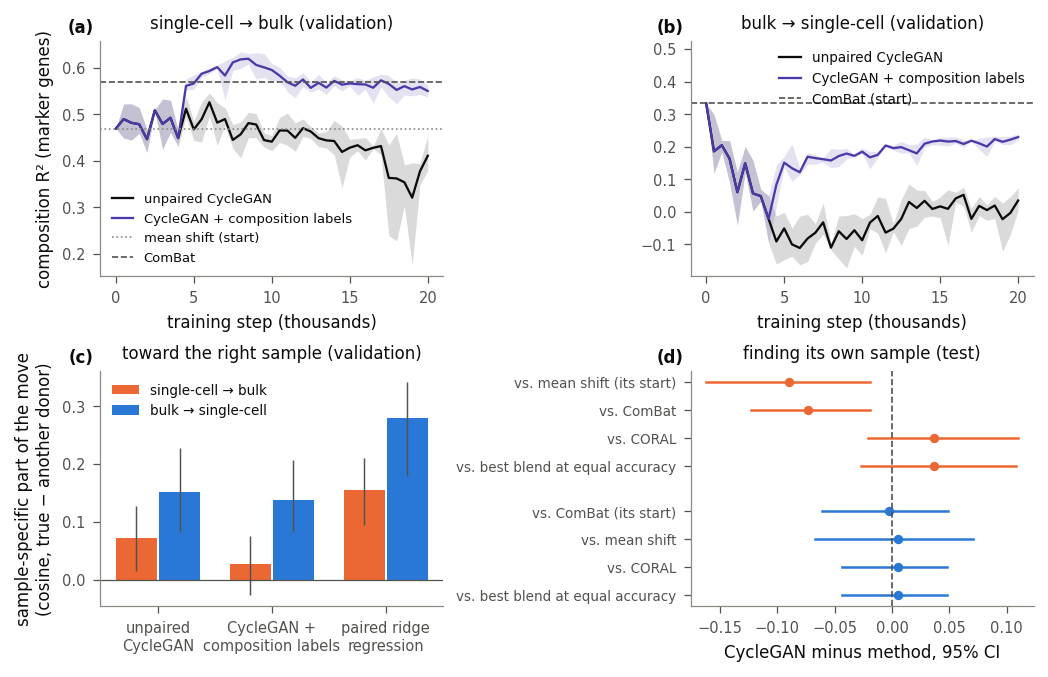

**Adversarial training lowers composition, and composition labels restore it in single-cell → bulk (to ComBat's level) and partly restore it in bulk → single-cell (validation); on test, the unpaired CycleGAN finds its own sample among the donor's draws no better than the simple alignments, and in single-cell → bulk less often than its own start.** (a, b) Validation (135 pairs, 14 donors): composition R² of the translations over training, read by the marker-gene readout, for the unpaired CycleGAN (black) and CycleGAN + composition labels (purple), on 3 fresh seeds (line: mean; band: range over seeds), with the composition of simple alignments as horizontal lines: (a) single-cell → bulk, with the mean-shift start (dotted) and ComBat (dashed); (b) bulk → single-cell, with the ComBat start (dashed). The composition loss starts at step 4,000 and reaches full weight at step 8,000. (c) Validation: how much of each model's move away from its start points toward the right sample: the median cosine between the move and the correction needed to reach the true partner, minus the same median with another donor's real profile in place of the partner; paired ridge regression for reference, with donor-bootstrap 95% CIs (1,000 resamples). (d) Test (119 pairs, 14 donors): the difference in the share of samples whose translation is closest to its own partner among the donor's draws, between the unpaired CycleGAN and each simple alignment or the best blend of two alignments at its accuracy, with paired donor-bootstrap 95% CIs; the dashed line marks no difference. In (c) and (d), orange is single-cell → bulk and blue is bulk → single-cell. In single-cell → bulk the unpaired CycleGAN is below its start (−0.090, 95% CI −0.162 to −0.019), the reverse of validation.

In [4]:
KEY4 = "4fb36e8a09c74f62"
P5_KEYS = ("identity_target", "identity_dirs", "lambda_dist", "bottleneck")
KEEP = (15000, 17500, 20000)
M1c = tr.config(lambda_cyc=20.0, identity=True); M2c = tr.config(lambda_cyc=20.0, identity=True, lambda_task=10.0)
abl4 = pd.read_csv(R[4] / "ablation_runs_val.csv")
def p4_run(cfg, seed, cond):
    c = {k: v for k, v in tr.config(**cfg).items() if k not in P5_KEYS}
    name = hashlib.sha256(json.dumps([KEY4, c, seed, 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    r = pickle.loads((paths.PROCESSED / "phase4" / f"run_{name}.pkl").read_bytes())
    row = abl4[(abl4.condition == cond) & (abl4.seed == seed)].iloc[0]
    for d in DIRS:                                              # provenance: equals Phase 4's per-run last-quarter means
        lq = np.mean([e[f"{d} marker comp_r2"] for e in r["evals"] if e["step"] >= 15000])
        assert abs(lq - row[f"{d} marker comp_r2"]) < 1e-9
    return r
fresh = {"M1": [p4_run(dict(M1c, ema=0.999, keep_states=KEEP), s, "full model") for s in (3, 4, 5)],
         "M2": [p4_run(dict(M2c, keep_states=KEEP), s, "B0 M2") for s in (3, 4, 5)]}
mv = pd.read_csv(R[6] / "move_decomposition_ci_val.csv")
wd = pd.read_csv(R[7] / "h1_within_donor_test.csv")
from dgm.baselines import ComBat, MeanShift
members = {d: {cls().name: cls().fit(*(((P.x_sc[ctx0.half_a], P.x_bulk[ctx0.half_b]) if d == "S->B" else (P.x_bulk[ctx0.half_b], P.x_sc[ctx0.half_a])))).translate(ctx0.src[d])
               for cls in (MeanShift, ComBat)} for d in DIRS}
Cv = P.composition[va]

fig = plt.figure(figsize=(6.875, 4.4), layout="constrained")
gs = fig.add_gridspec(2, 2)
ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
for a, d in zip(ax[:2], DIRS):
    for nm, col in (("M1", INK), ("M2", SERIES[6])):
        ev_ = np.array([[e[f"{d} marker comp_r2"] for e in r["evals"]] for r in fresh[nm]])
        steps = np.array([e["step"] for e in fresh[nm][0]["evals"]]) / 1000
        a.plot(steps, ev_.mean(0), color=col, lw=1.1, label=NAME[nm])
        a.fill_between(steps, ev_.min(0), ev_.max(0), color=col, alpha=0.15, lw=0)
    for nm, lab_, sty in ((("mean shift", "mean shift (start)", dict(color=MUTED, ls=":")), ("ComBat", "ComBat", dict(color=INK_2, ls="--")))
                          if d == "S->B" else (("ComBat", "ComBat (start)", dict(color=INK_2, ls="--")),)):
        a.axhline(comp.comp_r2(ctx0.marker[d].predict(members[d][nm]), Cv), lw=0.8, label=lab_, **sty)
    a.set(xlabel="training step (thousands)", ylabel="composition R² (marker genes)" if d == "S->B" else "", title=f"{label(d)} (validation)")
    if d == "S->B":
        a.legend(loc="lower left", fontsize=6.3, ncol=1, handlelength=1.6)
    else:                                                      # headroom above the ComBat line keeps the legend off the curves
        lo_, hi_ = a.get_ylim(); a.set_ylim(lo_, hi_ + 0.3 * (hi_ - lo_))
        a.legend(loc="upper right", fontsize=6.5, ncol=1, borderaxespad=0.3, handlelength=1.6)
names = ["M1, fresh seeds (raw)", "M2, fresh seeds (raw)", "ridge + spread (all training pairs)"]
xx = np.arange(len(names))
for k, d in enumerate(DIRS):
    t = mv[mv.direction == label(d)].set_index("translations").loc[names]
    lo = np.array([float(s.split(" to ")[0]) for s in t["sample-specific excess CI"]]); hi = np.array([float(s.split(" to ")[1]) for s in t["sample-specific excess CI"]])
    ax[2].bar(xx + (k - 0.5) * 0.38, t["sample-specific excess"], width=0.36, color=DIR_COL[d], label=label(d),
              yerr=[t["sample-specific excess"] - lo, hi - t["sample-specific excess"]], error_kw=dict(lw=0.7, ecolor=INK_2))
ax[2].axhline(0, color=INK_2, lw=0.6)
ax[2].set_xticks(xx, ["unpaired\nCycleGAN", "CycleGAN +\ncomposition labels", "paired ridge\nregression"])
ax[2].set(ylabel="sample-specific part of the move\n(cosine, true − another donor)", title="toward the right sample (validation)")
ax[2].legend(loc="upper left", fontsize=6.5)
order = ["mean shift (start)", "ComBat (start)", "ComBat", "mean shift", "CORAL", "matched blend"]
SHOW4 = {"mean shift (start)": "mean shift (its start)", "ComBat (start)": "ComBat (its start)", "ComBat": "ComBat", "mean shift": "mean shift",
         "CORAL": "CORAL", "matched blend": "best blend at equal accuracy"}
yy, labs = [], []
y = 0
for d in DIRS:
    t = wd[wd.direction == label(d)].set_index("M1 minus")
    for nm in [o for o in order if o in t.index]:
        lo, hi = (float(v) for v in t.loc[nm, "95% CI"].split(" to "))
        e = t.loc[nm, "difference"]
        ax[3].plot([lo, hi], [y, y], color=DIR_COL[d], lw=1.2)
        ax[3].plot([e], [y], "o", color=DIR_COL[d], ms=3.5)
        yy.append(y); labs.append(f"vs. {SHOW4[nm]}"); y -= 1
    y -= 0.6
ax[3].axvline(0, **THRESHOLD)
ax[3].set_yticks(yy, labs, fontsize=6.5)
ax[3].set(xlabel="CycleGAN minus method, 95% CI", title="finding its own sample (test)")
panel_labels(ax)
save_show(fig, FIG, "8.4_mechanism")
show_caption("8.4_mechanism")

**Figure 8.5 (qualitative): the unpaired CycleGAN spreads its translations over the real profiles, unlike its collapsed start, but its partner lines stay long, between those of its start and of a random real profile.** Every validation translation is shown in the top two target principal components (fit on the training targets), joined to its true partner, for the generator start, the unpaired CycleGAN, CycleGAN + composition labels, paired ridge regression and a random real profile; Figure 8.S2 shows the same view for bulk → single-cell.

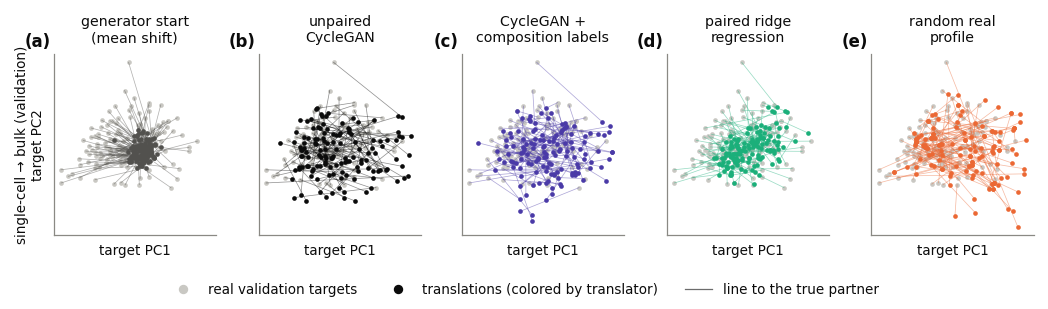

**The unpaired CycleGAN spreads its translations over the real profiles, unlike its collapsed start, but its partner lines stay long, between those of its start and of a random real profile; paired regression stays closest.** Each panel shows the 135 single-cell → bulk validation translations (14 donors) in the top two principal components of bulk profiles (fit on the training targets), over the real validation targets (gray), with a line from each translation to its true partner: (a) the generator start (mean shift), (b) the unpaired CycleGAN and (c) CycleGAN + composition labels (locked, seed 0), (d) paired ridge regression on all training pairs, and (e) one real training profile drawn at random per source. Overlap with the gray cloud gives a two-component view of realism (which is measured on 10 components); line length is the distance to the true partner within these two components (accuracy, centered R², is measured over all genes). Validation donors also chose the models; this figure is qualitative and no number is cited from it. Test results are in Figures 8.2–8.4.

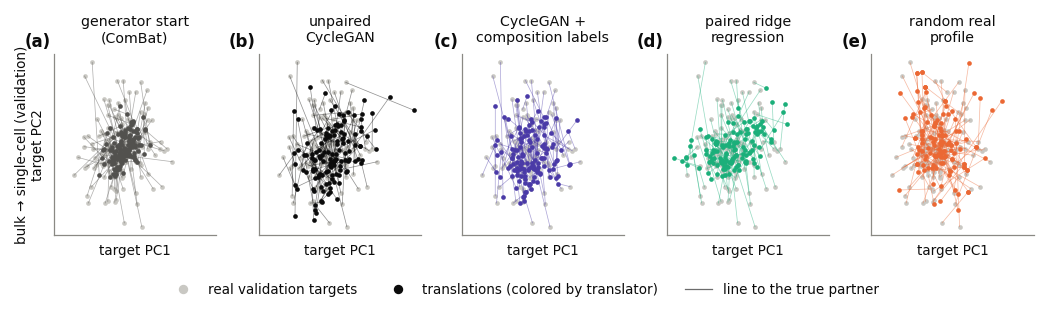

**The same view for bulk → single-cell.** As Figure 8.5, for the 135 bulk → single-cell validation translations (14 donors) in the top two principal components of single-cell pseudobulk profiles (fit on the training targets); the generator start is ComBat. Qualitative only; no number is cited from it.

In [5]:
FITS = paths.PROCESSED / "phase7" / "fits"                     # the Phase 7 fit cache, keyed by training rows only
BASE_CODE = hashlib.sha256((ROOT / "dgm" / "baselines.py").read_bytes()).hexdigest()[:12]
digest = pairs_hash(P)
tr_idx = rows("train")
def cached_fit(name, d, rows_s, rows_t):
    key = json.dumps([name, d, list_hash(np.sort(rows_s).tolist()), list_hash(np.sort(rows_t).tolist()), digest, BASE_CODE])
    return pickle.loads((FITS / f"{hashlib.sha256(key.encode()).hexdigest()[:16]}.pkl").read_bytes())
P3REG = json.loads((R[3] / "models.json").read_text())
p3 = pd.read_csv(R[3] / "models_vs_baselines_val.csv")
def locked(m):
    st = torch.load(paths.REPO / "data" / "models" / "phase3" / f"{m}_seed0.pt", weights_only=False)["state"]
    assert canonical_hash(st) == P3REG[f"{m}_seed0"]["canonical_hash"]
    return tr.load_generators(st, P.x_sc.shape[1], 512)
TRANS = {}
for d in DIRS:
    a0, b0 = ctx0.init[d]
    src_, tgt_ = ctx0.src[d], ctx0.tgt[d]
    TRANS[(d, "start")] = np.maximum(src_ * a0 + b0, 0)
    for m in ("M1", "M2"):
        g = locked(m)[0 if d == "S->B" else 1]
        with torch.no_grad():
            TRANS[(d, m)] = g(torch.as_tensor(src_)).numpy()
    TRANS[(d, "ridge + spread")] = cached_fit("ridge + spread", d, tr_idx, tr_idx).translate(src_)
    ht = np.asarray(ctx0.xb if d == "S->B" else ctx0.xs, float)
    TRANS[(d, "no-information reference")] = ht[np.random.default_rng([0, 7]).integers(len(ht), size=len(va))]
    ev = ctx0.ev[d]                                            # regeneration check against Phase 1's ridge + spread on validation
    r2 = np.median(1 - ((TRANS[(d, "ridge + spread")] - tgt_) ** 2).sum(1) / ((tgt_ - ev.mean_) ** 2).sum(1))
    want = p3[(p3.direction == label(d)) & (p3.method == "ridge + spread (all training pairs)")]["r2_centered"].iloc[0]
    assert abs(r2 - want) < 1e-6, (d, r2, want)

SHOW = {"start": "generator start", "M1": "unpaired\nCycleGAN", "M2": "CycleGAN +\ncomposition labels", "ridge + spread": "paired ridge\nregression",
        "no-information reference": "random real\nprofile"}
COL = {"start": INK_2, "M1": INK, "M2": SERIES[6], "ridge + spread": SERIES[2], "no-information reference": SERIES[1]}
for d, fname in (("S->B", "8.5_partner_lines"), ("B->S", "8.S2_partner_lines_bulk_to_single_cell")):
    pca, tgt_ = ctx0.ev[d].pca_, ctx0.tgt[d]
    zr = pca.transform(np.asarray(tgt_, float))[:, :2]
    fig, axs = figure("double", 1.95, 1, 5, sharex=True, sharey=True)
    for a, k in zip(axs, SHOW):
        start_name = "mean shift" if d == "S->B" else "ComBat"
        zh = pca.transform(np.asarray(TRANS[(d, k)], float))[:, :2]
        a.scatter(*zr.T, s=5, color="#c9c8c3", lw=0, zorder=1, rasterized=True)
        for i in range(len(zr)):
            a.plot([zh[i, 0], zr[i, 0]], [zh[i, 1], zr[i, 1]], color=COL[k], lw=0.35, alpha=0.45, zorder=2, rasterized=True)
        a.scatter(*zh.T, s=5, color=COL[k], lw=0, zorder=3, rasterized=True)
        a.set_title(f"generator start\n({start_name})" if k == "start" else SHOW[k], fontsize=6.8)
        a.set_xticks([]); a.set_yticks([])
        a.set_xlabel("target PC1", fontsize=6.5)
    axs[0].set_ylabel(f"{label(d)} (validation)\ntarget PC2", fontsize=6.5)
    fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=3.5, color="#c9c8c3", label="real validation targets"),
                        Line2D([], [], ls="", marker="o", ms=3.5, color=INK, label="translations (colored by translator)"),
                        Line2D([], [], color=INK, lw=0.6, alpha=0.6, label="line to the true partner")], loc="outside lower center", ncol=3, fontsize=6.5)
    panel_labels(axs)
    save_show(fig, FIG, fname)
    show_caption(fname)

**Figure 8.S3 (validation): the locked models against the unpaired frontier.** The webpage's development section shows the models as they were locked, on the validation donors that chose them, with the frontier of Phase 1.

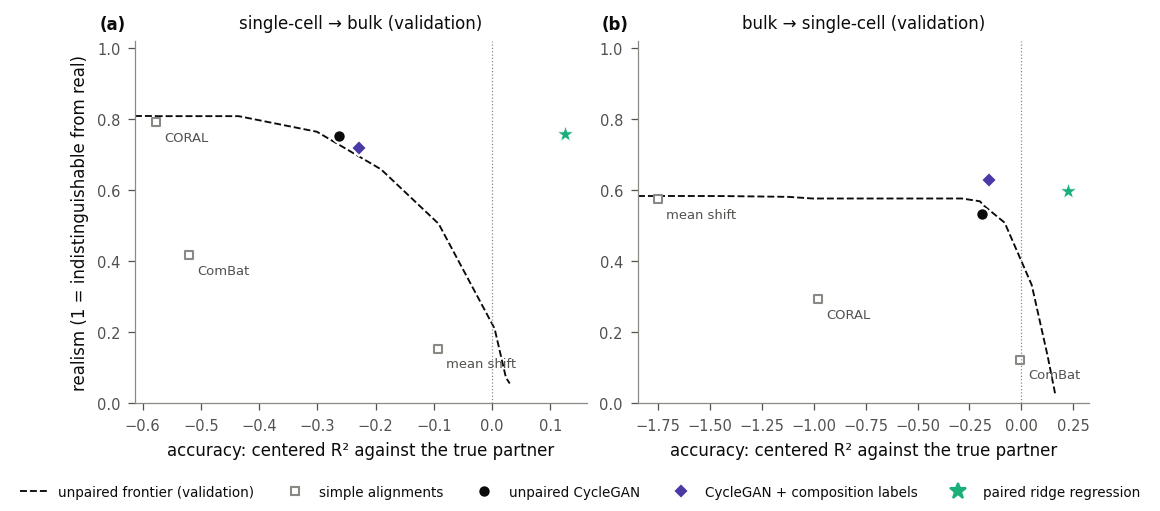

**On validation, the locked unpaired CycleGAN sits on the unpaired accuracy–realism frontier, not clearly beyond it.** As Figure 8.2, on the 135 validation pairs (14 donors) that chose the models: the frontier of blends of simple alignments fit on the training halves (dashed), mean shift, ComBat and CORAL (gray squares), the unpaired CycleGAN (black circle) and CycleGAN + composition labels (purple diamond) as locked (mean of 3 seeds, chosen checkpoints), and paired ridge regression on all training pairs (green star). Validation positions are optimistic for the CycleGANs, whose checkpoints were chosen on these donors.

In [6]:
# Figure 8.S3: the locked models against the unpaired frontier on validation (Phase 1 frontier, Phase 3 model positions)
fv = pd.read_csv(R[1] / "frontier_val_halves.csv")
fig, ax = figure("double", 3.3, 1, 2)
for a, d in zip(ax, DIRS):
    env = envelope(fv[(fv.halving == 0) & (fv.direction == d)])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=1)
    for n in ("mean shift", "ComBat", "CORAL"):
        r = p3[(p3.direction == label(d)) & (p3.method == f"{n} (training halves)")].iloc[0]
        a.scatter(r["r2_centered"], r["realism"], s=18, marker="s", facecolor="white", edgecolor=MUTED, lw=1, zorder=2)
        a.annotate(n, (r["r2_centered"], r["realism"]), xytext=(4, -9), textcoords="offset points", fontsize=6.3, color=INK_2)
    for n, sty in (("M1", STY["M1"]), ("M2", STY["M2"])):
        r = p3[(p3.direction == label(d)) & (p3.method == f"{n} (mean of 3 seeds)")].iloc[0]
        a.plot([r["r2_centered"]], [r["realism"]], ls="", zorder=5, **sty)
    r = p3[(p3.direction == label(d)) & (p3.method == "ridge + spread (all training pairs)")].iloc[0]
    a.scatter(r["r2_centered"], r["realism"], s=70, marker="*", color=SERIES[2], edgecolor="white", lw=0.4, zorder=4)
    a.axvline(0, color=MUTED, lw=0.6, ls=":")
    x_lo = a.get_xlim()[0]
    a.plot([x_lo, env["r2_centered"].iloc[0]], [env["realism"].iloc[0]] * 2, color=INK, lw=0.9, ls="--", zorder=1)
    a.set_xlim(left=x_lo)
    a.set(xlabel="accuracy: centered R² against the true partner", ylabel="realism (1 = indistinguishable from real)" if d == "S->B" else "",
          title=f"{label(d)} (validation)", ylim=(0, 1.02))
fig.legend(handles=[Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier (validation)"),
                    Line2D([], [], ls="", marker="s", mfc="white", mec=MUTED, label="simple alignments"),
                    Line2D([], [], ls="", label=NAME["M1"], **STY["M1"]), Line2D([], [], ls="", label=NAME["M2"], **STY["M2"]),
                    Line2D([], [], ls="", marker="*", ms=8, color=SERIES[2], label=NAME["ridge + spread"])], loc="outside lower center", ncol=5, fontsize=6.5)
panel_labels(ax)
save_show(fig, FIG, "8.S3_validation_plane")
show_caption("8.S3_validation_plane")

### 4.3 Tables and cited numbers

**Table 1.** Main results on the test split (119 pairs, 14 donors), per direction: whether the unpaired CycleGAN is beyond the frontier (its margin), whether composition labels help (CycleGAN + composition labels minus the unpaired CycleGAN in composition R²), what pairs add (paired ridge regression minus each CycleGAN in centered R² and composition R², no claim), the exploratory CycleGAN + cross-fitted labels minus the unpaired CycleGAN with averaged weights, and the margin of a random real profile; each with its estimate, paired donor-bootstrap 95% CI (1,000 resamples) and pre-stated reading. **Table 2.** Every model on the test split (point estimates): centered R², realism, margin and its kind, composition R², within-donor top-1 rate and nearest-neighbor ratio.

The cell below writes both tables and prints the start of Table 1; the next writes one LaTeX macro per number the report cites. Every value is read from a results table and checked against its source; readings and labels from the result tables have their short model names replaced by descriptive ones.

In [7]:
h1 = pd.read_csv(R[7] / "h1_test.csv"); h2 = pd.read_csv(R[7] / "h2_test.csv"); h3 = pd.read_csv(R[7] / "h3_test.csv")
bcf = pd.read_csv(R[7] / "bcf_test.csv"); refs = pd.read_csv(R[7] / "references_test.csv"); sup = pd.read_csv(R[7] / "h1_superseded_test.csv")
models = pd.read_csv(R[7] / "models_test.csv"); count = pd.read_csv(R[6] / "configuration_count.csv")
SB, BS = label("S->B"), label("B->S")
by = lambda t, d: t[t.direction == d].iloc[0]
num, ci = rp.num, rp.ci
def cis(s):
    lo, hi = (float(v) for v in s.split(" to ")); return lo, hi

# Table 1: main test results (readings and labels verbatim from the CSVs)
t1 = []
for d in (SB, BS):
    a = by(h1, d)
    t1.append([d, "Beyond the frontier? Unpaired CycleGAN's margin", num(a["margin"], sign=True), ci(*cis(a["95% CI"])), a["reading"]])
for d in (SB, BS):
    a = by(h2, d)
    t1.append([d, "Do composition labels help? CycleGAN + composition labels $-$ unpaired CycleGAN, composition $R^2$", num(a["difference"], sign=True), ci(*cis(a["95% CI"])),
               a["reading"] + ("$^{a}$" if isinstance(a["label"], str) and a["label"] else "") + "$^{c}$"])
for d in (SB, BS):
    for m in ("M1", "M2"):
        for metric, short in (("centered R²", "centered $R^2$"), ("marker composition R²", "composition $R^2$")):
            a = h3[(h3.direction == d) & (h3["ridge + spread minus"] == m) & (h3.metric == metric)].iloc[0]
            t1.append([d, f"What pairs buy: paired ridge regression $-$ {NAME[m]}, {short}", num(a["difference"], sign=True), ci(*cis(a["95% CI"])), "no claim"])
for d in (SB, BS):
    for metric, short in (("marker composition R²", "composition $R^2$"), ("centered R²", "centered $R^2$")):
        a = bcf[(bcf.direction == d) & (bcf["B-cf minus"] == "M1 (EMA)") & (bcf.metric == metric)].iloc[0]
        t1.append([d, f"CycleGAN + cross-fitted labels $-$ unpaired CycleGAN (averaged weights), {short}", num(a["difference"], sign=True), ci(*cis(a["95% CI"])), "exploratory$^{b}$"])
for d in (SB, BS):
    a = refs[(refs.direction == d) & (refs.reference == "no-information reference")].iloc[0]
    t1.append([d, "Random real profile's margin", num(a["margin"], sign=True), "--", "reference"])
n_te, d_te = int((np.asarray(P.split) == "test").sum()), len(np.unique(P.donor_ids[np.asarray(P.split) == "test"]))
h1_supported = any(r.startswith("supported") for r in (by(h1, SB)["reading"], by(h1, BS)["reading"]))
sup_sb, sup_bs = by(sup, SB)["reading"], by(sup, BS)["reading"]
sup_txt = f"{sup_sb} in both directions" if sup_sb == sup_bs else f"{sup_sb} ({SB}); {sup_bs} ({BS})"
settings = lambda t: describe(by(t, SB)["settings compared"])
foot = (f"Estimates with paired donor-bootstrap 95\\% CIs (1,000 resamples of the test donors), not corrected for multiple comparisons. "
        f"Composition $R^2$ is read by a marker-gene readout independent of the composition networks; accuracy is centered $R^2$ against the true partner. "
        f"Margin: realism minus the unpaired frontier's realism at the same accuracy. "
        f"Robustness: on a second split of the training donors, the unpaired CycleGAN's margins were "
        f"{num(by(h1, SB)['halving-1 margin (point estimate)'], sign=True)} ({SB}) and {num(by(h1, BS)['halving-1 margin (point estimate)'], sign=True)} ({BS})"
        + " (point estimates). "
        f"The original hypothesis (beat the most accurate simple method on accuracy and the most realistic one on realism, separately) {sup_txt}. "
        f"Settings compared on validation: {settings(h1)}; {settings(h2)}. "
        f"$^{{a}}$ The generator partly fits the network it trained against: on validation, less than half of its composition gain under that network was confirmed by the marker-gene readout (a point estimate; its interval includes one half). "
        f"$^{{b}}$ Exploratory: designed after 56 settings and 160 runs on validation, with no check on a second split of the training donors, and it also partly fits the network it trained against, in both directions. "
        f"$^{{c}}$ {describe(by(h2, SB)['note'])[0].upper() + describe(by(h2, SB)['note'])[1:]}.")
assert not h1_supported and by(h2, SB)["label"].startswith("the generator partly fits its training readout") and "56 settings and 160 runs" in bcf["labels"].iloc[0]
TAB1 = rp.latex_table(["Direction", "Comparison", "Estimate", "95\\% CI", "Reading"], t1, "llrll",
                      caption=f"Main results on the test split ({n_te} pairs, {d_te} donors). " + foot, label="tab:main")
(REPORT / "tables" / "table1_main.tex").write_text(TAB1.replace("→", "$\\to$"))

# Table 2: every model on test
SHOWN = {"M1": "unpaired CycleGAN (chosen checkpoint)", "M2": "CycleGAN + composition labels (chosen checkpoint)",
         "M1 (EMA)": "unpaired CycleGAN (averaged weights)", "M2 (EMA)": "CycleGAN + composition labels (averaged weights)",
         "B-cf (EMA)": "CycleGAN + cross-fitted labels (averaged weights)", "mean shift": "mean shift", "ComBat": "ComBat", "CORAL": "CORAL",
         "ridge + spread": "paired ridge regression", "paired MLP": "paired neural network", "OT-s": "optimal-transport retrieval",
         "no-information reference": "random real profile", "same-donor reference": "another draw of the same donor"}
KIND = {"acc.": "accuracy", "real.": "realism", "real.$^{\\dagger}$": "realism$^{\\dagger}$", "mixed": "mixed"}
# Margin kind: a margin is of the accuracy kind when no blend is as accurate, and then equals R² minus the frontier's
# highest accuracy. That accuracy is recovered from two paired models whose margins are of that kind and must agree.
MULTI = {"M1", "M2", "M1 (EMA)", "M2 (EMA)", "B-cf (EMA)", "paired MLP", "OT-s", "no-information reference"}
TOP = {}
for d in (SB, BS):
    m_ = models[models.direction == d].set_index("model")
    tops = [m_.loc[k, "r2_centered"] - m_.loc[k, "margin"] for k in ("ridge", "ridge + spread")]
    assert abs(tops[0] - tops[1]) < 1e-9, tops
    TOP[d] = tops[0]
    assert (m_["r2_centered"] > TOP[d]).sum() >= 2
def kind_of(r, d):
    """acc. when the margin is the accuracy lead (identity holds); mixed when a multi-member model's mean accuracy is above
    the frontier's top but its members' margins mix kinds; real. otherwise."""
    if abs(r["r2_centered"] - r["margin"] - TOP[d]) < 1e-9:
        return "acc."
    return "mixed" if r["r2_centered"] > TOP[d] else ("real.$^{\\dagger}$" if r.get("model", "") in MULTI else "real.")
_sd = refs[(refs.direction == SB) & (refs.reference == "same-donor reference")].iloc[0]
assert kind_of({"r2_centered": _sd["centered R²"], "margin": _sd["margin"]}, SB) == "acc."   # as in Phase 7, Table 7.4
t2 = []
for d in (SB, BS):
    for k, show in SHOWN.items():
        r = models[(models.direction == d) & (models.model == k)].iloc[0]
        kind = kind_of(r, d)
        desc = "$^{*}$" if k in ("ridge + spread", "paired MLP") else ""
        t2.append([d if k == "M1" else "", show, num(r["r2_centered"]), num(r["realism"]), num(r["margin"], sign=True) + desc, KIND[kind],
                   num(r["marker composition R²"]), num(r["within_top1"]), num(r["nn_ratio"])])
TAB2 = rp.latex_table(["Direction", "Model", "Centered $R^2$", "Realism", "Margin", "Margin kind", "Composition $R^2$", "Within-donor top-1", "Nearest-neighbor ratio"], t2, "llrrrlrrr",
                      caption=f"Every model on the test split ({n_te} pairs, {d_te} donors; point estimates). Chosen checkpoint: the models locked before test, at the checkpoints chosen on validation (seeds 0--2); "
                              "averaged weights: exponential-moving-average weights, with no checkpoint selection (seeds 6--8, steps 15,000, 17,500 and 20,000). "
                              "Realism: $1 - 2\\lvert\\mathrm{AUROC} - 0.5\\rvert$ of a classifier two-sample test. "
                              "Margin: the distance beyond the unpaired frontier, in realism units (realism kind: realism minus the frontier's realism at the model's accuracy), "
                              "or in centered $R^2$ units when no blend is as accurate (accuracy kind); mixed: members of different kinds averaged. "
                              "$^{\\dagger}$Inferred for models averaged over several members: their mean accuracy is below the frontier's highest accuracy. "
                              "$^{*}$Paired models' margins are descriptive. Composition $R^2$: read by the marker-gene readout. "
                              "Within-donor top-1: the share of samples whose translation is closest to its own partner among the donor's draws. "
                              "Nearest-neighbor ratio: the median distance from a translation to its nearest training target, over the same for the real targets. "
                              "Zeros that hold by construction: the nearest-neighbor ratio of optimal-transport retrieval and the random real profile (they output training profiles) "
                              "and the within-donor top-1 of another draw of the same donor.",
                      label="tab:models")
(REPORT / "tables" / "table2_models.tex").write_text(TAB2.replace("→", "$\\to$"))
for t_ in (TAB1, TAB2):
    assert not SHORT_NAMES.search(t_), SHORT_NAMES.search(t_)
print(TAB1[:1500])

\begin{table*}[t]
\centering
\small
\begin{tabular}{llrll}
\toprule
Direction & Comparison & Estimate & 95\% CI & Reading \\
\midrule
single-cell → bulk & Beyond the frontier? Unpaired CycleGAN's margin & +0.105 & $-$0.259 to 0.290 & not distinguishable from the unpaired frontier \\
bulk → single-cell & Beyond the frontier? Unpaired CycleGAN's margin & $-$0.372 & $-$0.705 to $-$0.006 & inside the unpaired frontier \\
single-cell → bulk & Do composition labels help? CycleGAN + composition labels $-$ unpaired CycleGAN, composition $R^2$ & +0.174 & 0.108 to 0.331 & supported$^{a}$$^{c}$ \\
bulk → single-cell & Do composition labels help? CycleGAN + composition labels $-$ unpaired CycleGAN, composition $R^2$ & +0.140 & 0.079 to 0.267 & supported$^{c}$ \\
single-cell → bulk & What pairs buy: paired ridge regression $-$ unpaired CycleGAN, centered $R^2$ & +0.375 & 0.302 to 0.478 & no claim \\
single-cell → bulk & What pairs buy: paired ridge regression $-$ unpaired CycleGAN, composition $R^2

In [8]:
# The numbers the report cites, as LaTeX macros, each asserted equal to its CSV value when re-read.
M = {}
def put(name_words, value, **kw):
    M[rp.macro_name(*name_words)] = num(value, **kw)
for d, tag in ((SB, "SB"), (BS, "BS")):
    a = by(h1, d)
    put(("H1", tag, "margin"), a["margin"], sign=True)
    lo, hi = cis(a["95% CI"]); put(("H1", tag, "lo"), lo); put(("H1", tag, "hi"), hi)
    put(("H1", tag, "halving one"), a["halving-1 margin (point estimate)"], sign=True)
    put(("M1", tag, "realism"), a["M1 realism"]); put(("M1", tag, "accuracy"), a["M1 centered R²"]); put(("frontier", tag, "at M1"), a["frontier at M1's accuracy"])
    a = by(h2, d); put(("H2", tag, "diff"), a["difference"], sign=True); lo, hi = cis(a["95% CI"]); put(("H2", tag, "lo"), lo); put(("H2", tag, "hi"), hi)
    for m in ("M1", "M2"):
        for metric, short in (("centered R²", "acc"), ("marker composition R²", "comp")):
            a = h3[(h3.direction == d) & (h3["ridge + spread minus"] == m) & (h3.metric == metric)].iloc[0]
            put(("H3", tag, m, short), a["difference"], sign=True); lo, hi = cis(a["95% CI"]); put(("H3", tag, m, short, "lo"), lo); put(("H3", tag, m, short, "hi"), hi)
    for metric, short in (("marker composition R²", "comp"), ("centered R²", "acc")):
        a = bcf[(bcf.direction == d) & (bcf["B-cf minus"] == "M1 (EMA)") & (bcf.metric == metric)].iloc[0]
        put(("Bcf", tag, short), a["difference"], sign=True); lo, hi = cis(a["95% CI"]); put(("Bcf", tag, short, "lo"), lo); put(("Bcf", tag, short, "hi"), hi)
    a = refs[(refs.direction == d) & (refs.reference == "no-information reference")].iloc[0]; put(("noinfo", tag, "margin"), a["margin"], sign=True)
    for comp_name, short in (("mean shift (start)", "start"), ("ComBat (start)", "start"), ("ComBat", "combat"), ("CORAL", "coral")):
        t = wd[(wd.direction == d) & (wd["M1 minus"] == comp_name)]
        if len(t):
            put(("within", tag, short), t["difference"].iloc[0], sign=True); lo, hi = cis(t["95% CI"].iloc[0])
            put(("within", tag, short, "lo"), lo); put(("within", tag, short, "hi"), hi)
is_test = np.asarray(P.split) == "test"                       # split labels only; no test expression is read
M["NTestPairs"], M["NTestDonors"] = str(int(is_test.sum())), str(len(np.unique(P.donor_ids[is_test])))
M["NValPairs"], M["NValDonors"] = str(len(va)), str(len(np.unique(P.donor_ids[va])))
M["NTrainPairs"] = str(len(rows("train")))
M["NSettings"], M["NRuns"] = str(int(count[count.phase == "total"]["settings"].iloc[0])), str(int(count[count.phase == "total"]["runs"].iloc[0]))
(REPORT / "numbers.tex").write_text(rp.macros(M))
assert float(M["HOneSBMargin"].replace("$-$", "-")) == round(float(by(h1, SB)["margin"]), 3)   # spot checks against the CSVs
assert M["HTwoBSDiff"].replace("$-$", "-") == f"{by(h2, BS)['difference']:+.3f}"
print(len(M), "macros written to report/numbers.tex")

80 macros written to report/numbers.tex


### 4.4 Results webpage

The static, self-contained page leads with the pre-stated readings, then gives definitions, an overview figure (drawn by `scripts/make_overview_figure.py`), a section on the unpaired accuracy–realism frontier (what it is, why it is computed this way, its precedents and its known biases), the test accuracy–realism plane, what pairs add, the partner-line views (with a direction selector), the mechanism, Table 1 and the sortable Table 2, the validation-stage results and the limitations. The cell below copies its figures and writes the data file from which the page fills every number; the page itself holds no typed result numbers.

In [9]:
FIGS_WEB = {"plane": FIG / "8.2_test_plane.png", "pairs": FIG / "8.3_what_pairs_buy_test.png",
            "mechanism": FIG / "8.4_mechanism.png", "lines_sb": FIG / "8.5_partner_lines.png", "lines_bs": FIG / "8.S2_partner_lines_bulk_to_single_cell.png",
            "intervals": FIG / "8.S1_test_intervals.png", "gap": R[0] / "figures" / "0.11_domain_gap.png", "granulocytes": R[0] / "figures" / "0.10_granulocyte_genes.png", "plane_val": FIG / "8.S3_validation_plane.png"}
for k, f in FIGS_WEB.items():
    shutil.copyfile(f, WEB / "assets" / f"{k}.png")
for k in ("ablations", "tracka", "pairs_val", "ladder"):         # no longer on the page: short-name labels, or replaced by the overview figure
    (WEB / "assets" / f"{k}.png").unlink(missing_ok=True)
def row(d, comparison, est, ci_s, reading):
    return {"direction": d, "comparison": comparison, "estimate": est, "ci": ci_s, "reading": reading}
plain = lambda s: s.replace("$-$", "−").replace("$R^2$", "R²").replace("$^{a}$", " (a)").replace("$^{b}$", " (b)").replace("$^{c}$", " (c)")
DATA = {"numbers": {k: v.replace("$-$", "−") for k, v in M.items()},
        "readings": {"H2_note": by(h2, SB)["note"], "H1_SB": by(h1, SB)["reading"], "H1_BS": by(h1, BS)["reading"], "H2_SB": by(h2, SB)["reading"], "H2_BS": by(h2, BS)["reading"],
                     "H2_label": by(h2, SB)["label"], "superseded_SB": by(sup, SB)["reading"], "superseded_BS": by(sup, BS)["reading"]},
        "table1": [dict(zip(["direction", "comparison", "estimate", "ci", "reading"], [plain(str(c)) for c in r])) for r in t1],
        "table2": [dict(zip(["direction", "model", "r2", "realism", "margin", "kind", "composition", "within", "nn"], [plain(str(c)).replace("$^{*}$", "*").replace("$^{\\dagger}$", "†") for c in r])) for r in t2],
        "foot": " ".join(plain(f"Test split ({n_te} pairs, {d_te} donors). " + foot).replace("\\%", "%").split())}
DATA["readings"] = {k: describe(v) for k, v in DATA["readings"].items()}

# Biology numbers for the page's assay section, read from their result tables (the report does not cite them, so they are not in numbers.tex)
wv = pd.read_csv(R[0] / "composition_within_donor_variance.csv", index_col=0)["within-donor share of variance"]
lin = pd.read_csv(R[6] / "lineage_composition_val.csv")
dc = pd.read_csv(R[2] / "deconv_check_train.csv")
dc0 = dc[(dc.halving == 0) & (dc.signature == "counts") & (~dc["background column"]) & (dc.input == "real bulk")].iloc[0]
pbt = pd.read_csv(R[7] / "pairs_buy_test.csv")
f2 = lambda v: f"{v:.2f}".replace("-", "−")
lin_ = lambda d, t, cls: lin[(lin.direction == label(d)) & (lin.translations == t)][cls].iloc[0]
gran = lambda n: models[(models.direction == SB) & (models.model == n)]["granulocyte r"].iloc[0]
pb_ = lambda d, meth, k: pbt[(pbt.direction == label(d)) & (pbt.method == meth) & (pbt.k == k) & (pbt.metric == "centered R²")]["value"].iloc[0]
major = ["T cell", "Monocyte", "B cell", "NK cell", "DC"]
BIO = {"BioWithinLo": f"{100 * wv[major].min():.0f}%", "BioWithinHi": f"{100 * wv[major].max():.0f}%",
       "BioCompBulk": f2(refs[(refs.direction == SB) & (refs.reference == "real targets read by the marker probe")]["composition R²"].iloc[0]),
       "BioCompSC": f2(refs[(refs.direction == BS) & (refs.reference == "real targets read by the marker probe")]["composition R²"].iloc[0]),
       "BioTStart": f2(lin_("S->B", "start: mean shift", "T")), "BioTGAN": f2(lin_("S->B", "M1 (EMA)", "T")),
       "BioGranGAN": f2(gran("M1")), "BioGranMS": f2(gran("mean shift")), "BioGranRidge": f2(gran("ridge + spread")),
       "BioGranSame": f2(gran("same-donor reference")), "BioGranRandom": f2(gran("no-information reference")),
       "BioDeconvRLo": f2(min(dc0[f"r {c}"] for c in major[:4])), "BioDeconvRHi": f2(max(dc0[f"r {c}"] for c in major[:4])),
       "BioDeconvT": f"{-100 * dc0['bias T cell']:.0f}", "BioDeconvMono": f"{100 * dc0['bias Monocyte']:.0f}",
       "BioRidge8SB": f2(pb_("S->B", "ridge", 8)), "BioGAN68SB": f2(pb_("S->B", "weakly paired GAN (EMA)", 68)),
       "BioRidge8BS": f2(pb_("B->S", "ridge", 8)), "BioGAN68BS": f2(pb_("B->S", "weakly paired GAN (EMA)", 68))}
assert BIO["BioDeconvT"] == "14" and BIO["BioDeconvMono"] == "7" and BIO["BioTStart"] == "0.76"   # as written in the README
DATA["numbers"].update(BIO)
js = json.dumps(DATA, ensure_ascii=False, indent=1)
assert not SHORT_NAMES.search(js), SHORT_NAMES.search(js)
(WEB / "assets" / "data.js").write_text("window.DATA = " + js + ";\n")
assert len(json.loads(TOUCH.read_text())) == 2, "test was not touched"
print("webpage assets and data written;", len(DATA["table1"]), "rows in table 1")

webpage assets and data written; 18 rows in table 1


## 5. Conclusions

This phase adds no new result. The report's figures, tables and cited numbers reproduce the Phase 7 test results exactly, and every number is generated from a result table rather than typed.

- **The unpaired CycleGAN is not beyond the frontier:** it is not distinguishable from the frontier in single-cell → bulk (+0.105, 95% CI −0.259 to 0.290) and lies inside it in bulk → single-cell (−0.372, 95% CI −0.705 to −0.006).
- **Composition labels help in both directions** (+0.174, 95% CI 0.108–0.331; +0.140, 95% CI 0.079–0.267).
- **Pairs as regression targets buy accuracy** (descriptive): paired ridge regression exceeds the unpaired CycleGAN by +0.375 (95% CI 0.302–0.478) and +0.515 (95% CI 0.406–0.682) in centered R².
- **Mechanism (Figure 8.4):** on test, in single-cell → bulk, the unpaired CycleGAN identifies its sample among the donor's draws less often than its own start (−0.090, 95% CI −0.162 to −0.019), the reverse of validation.

## 6. Limitations

- The test frontier in Figure 8.2 is traced from Phase 7's drawn curve, a polyline simplified by the plotting library; it matches the saved frontier value at the unpaired CycleGAN's accuracy within 0.005, and no number is read from the traced curve.
- Figures 8.4(a–c), 8.5 and 8.S2 are on the validation donors that also chose the models; Figures 8.5 and 8.S2 are qualitative, and their two components show only part of what realism and accuracy measure (10 components and all genes).
- Figure 8.4 combines validation panels (a–c) with a test panel (d); each panel names its split.
- The margin kinds of models averaged over several members are inferred from their mean accuracy, not computed per member (marked † in Table 2).

## 7. Reproducibility

- **Runtime and hardware:** a few minutes on CPU; no model is trained.
- **Determinism:** seed 0 (setup stamp), deterministic CPU algorithms (`dgm.composition.deterministic`), and fixed seeds for the random real profiles of Figure 8.5.
- **Inputs:** `results/phase0`–`phase7` (CSVs, and Phase 7's Figure 7.1 PDF for the frontier path), the saved Phase 3 generators (checked against their registry hashes), the Phase 4 run logs (checked against Phase 4's per-run table) and the Phase 7 fit cache for ridge + spread (`data/processed/phase7/fits`, keyed by training rows only). No cache is written here; the traced test frontier is saved as `results/phase8/test_frontier_traced.csv`. Test rows are never selected, and the test-touch record is asserted unchanged at the start and the end.
- **Outputs:** report figures in `results/phase8/figures/` (captions in `captions.md`); LaTeX tables in `report/tables/` (`table1_main.tex`, `table2_models.tex`); cited numbers in `report/numbers.tex` (one macro per value); the webpage's figures and data in `assets/` (the page, `index.html`, fills every number from `assets/data.js`). The report numbering of each figure and table is in `report/figure_register.md`.
- **Code:** `dgm/report.py` (number formatting, macros, tables); known-answer tests: `python -m tests.test_phase8`.

## References

- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).